# Parte 1 — Representação de uma fotografia por três cores

**Autor:** Tiago. **Disciplina:** Programação Não Linear — UFC.

O objetivo é ajustar uma paleta de três cores RGB para representar uma fotografia. As nove componentes da paleta são as variáveis de decisão; os pixels são dados fixos.

**Imagem:** `nascer do sol rio de janeiro.jpeg`. **Fonte: acervo pessoal do autor.**

Este notebook contém preparação dos dados, formulação irrestrita, deduções de gradiente e Hessiana, análise de convexidade, verificação por diferenças finitas e **um passo** de descida com busca de Goldstein implementada diretamente. Não se exige convergência completa nesta parte.

**Manual de uso:** execute todas as células na ordem com um kernel Python 3, pela pasta deste notebook ou pela raiz do repositório. Dependências: NumPy, Pillow, Matplotlib e um ambiente Jupyter. Se necessário, instale com `%pip install numpy pillow matplotlib` em uma célula separada. Para abrir pelo terminal: `python -m pip install numpy pillow matplotlib notebook` e `python -m notebook`. Selecione este notebook e use *Restart Kernel and Run All Cells*.

**Entradas configuráveis:** `NOME_IMAGEM`, `LADO_MAXIMO`, `TAU` e os parâmetros explícitos da busca. Ao mudar a fotografia, confira também os diagnósticos de derivadas e convexidade: os resultados numéricos apresentados aqui são específicos da imagem escolhida.

**Saídas:** figuras e valores exibidos nas células; arquivos PNG e JSON em `resultados/parte1`, ao lado do notebook. As reconstruções usam a resolução de trabalho, sem substituir a fotografia original. Os arquivos gerados são atualizados a cada execução.

## 1. Bibliotecas e parâmetros de preparação

Adotamos **256 pixels no maior lado**, preservando a proporção e sem ampliar imagens menores. Esse limite é uma escolha de custo computacional, não uma exigência do professor. O filtro LANCZOS combina informações dos pixels durante a redução; portanto, os dados usados no modelo serão os pixels da versão reduzida.

O código encontra a fotografia ao executar o notebook pela pasta do trabalho ou pela raiz do repositório.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

NOME_IMAGEM = "nascer do sol rio de janeiro.jpeg"
LADO_MAXIMO = 256

candidatos = [
    Path(NOME_IMAGEM),
    Path("programacao nao linear") / "trabalho 1" / NOME_IMAGEM,
]
caminho_imagem = next((p for p in candidatos if p.is_file()), None)
if caminho_imagem is None:
    raise FileNotFoundError(
        "Fotografia não encontrada. Execute pela pasta do notebook ou pela raiz "
        "do repositório, ou ajuste candidatos para indicar a pasta da imagem."
    )

## 2. Carregar e mostrar a fotografia original

Corrigimos a orientação indicada pelos metadados EXIF, quando houver, e convertemos a imagem para RGB. A fotografia original no disco permanece intacta. A figura abaixo mostra a imagem completa, ajustada ao tamanho da tela.

Resolução original: 3024 × 4032 pixels
Modo de cor: RGB


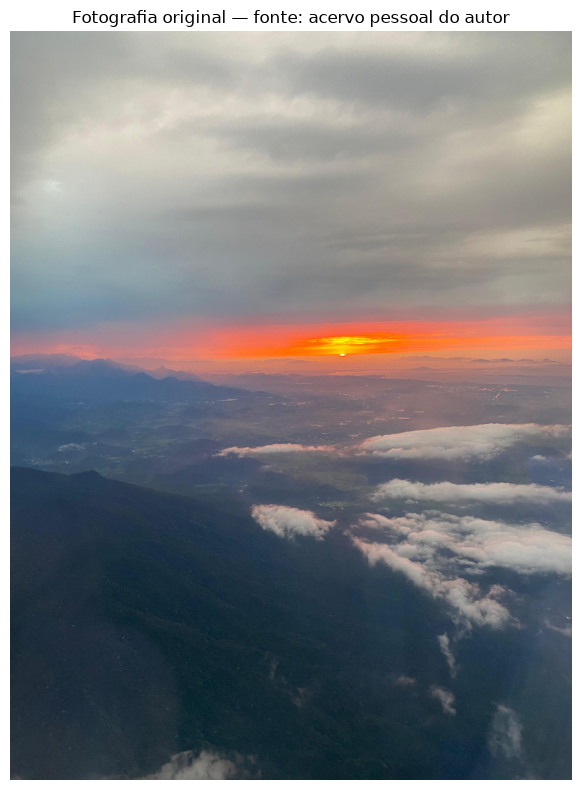

In [2]:
with Image.open(caminho_imagem) as arquivo:
    imagem_original = ImageOps.exif_transpose(arquivo).convert("RGB")

largura_original, altura_original = imagem_original.size
print(f"Resolução original: {largura_original} × {altura_original} pixels")
print(f"Modo de cor: {imagem_original.mode}")

fig, ax = plt.subplots(figsize=(6, 8))
ax.imshow(imagem_original)
ax.set_title("Fotografia original — fonte: acervo pessoal do autor")
ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Criar uma versão menor preservando a proporção

A redução é feita sobre uma cópia em memória. A largura e a altura são inteiras, de modo que outras imagens podem apresentar um pequeno arredondamento na proporção.

Resolução de trabalho: 192 × 256 pixels
Pixels: 12,192,768 → 49,152
Redução da quantidade de pixels: 99.60%


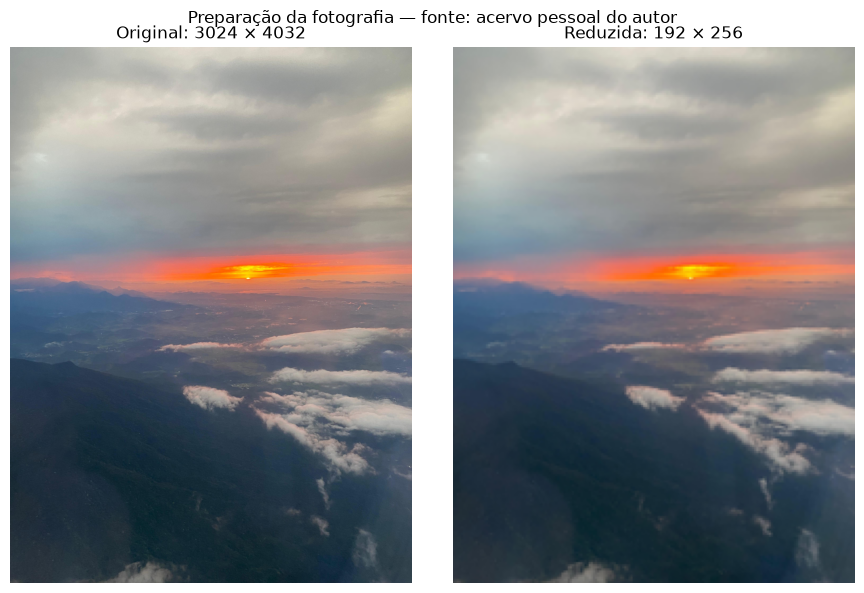

In [3]:
imagem_reduzida = imagem_original.copy()
imagem_reduzida.thumbnail(
    (LADO_MAXIMO, LADO_MAXIMO), resample=Image.Resampling.LANCZOS
)

largura, altura = imagem_reduzida.size
total_original = largura_original * altura_original
total_reduzido = largura * altura
print(f"Resolução de trabalho: {largura} × {altura} pixels")
print(f"Pixels: {total_original:,} → {total_reduzido:,}")
print(f"Redução da quantidade de pixels: {100 * (1 - total_reduzido / total_original):.2f}%")

fig, eixos = plt.subplots(1, 2, figsize=(9, 6))
for ax, imagem, titulo in zip(
    eixos,
    (imagem_original, imagem_reduzida),
    (f"Original: {largura_original} × {altura_original}",
     f"Reduzida: {largura} × {altura}"),
):
    ax.imshow(imagem)
    ax.set_title(titulo)
    ax.axis("off")
fig.suptitle("Preparação da fotografia — fonte: acervo pessoal do autor")
plt.tight_layout()
plt.show()

## 4. Normalizar o RGB e organizar a matriz de pixels

Cada componente inteira de 0 a 255 é dividida por 255 e armazenada em ponto flutuante de 64 bits. Assim, os componentes passam para o intervalo $[0,1]$ e são adimensionais.

A imagem tem formato `(altura, largura, 3)`. A matriz `pixels` tem formato `(N, 3)`, com $N=\text{altura}\times\text{largura}$: cada linha contém `[R, G, B]` de um pixel. O percurso é por linhas da imagem, preservando a ordem necessária para reconstruí-la depois.

Usaremos as diferenças no RGB normalizado da imagem, sem conversão para um espaço perceptual ou linearização de gamma. Essa distância é uma simplificação: diferenças iguais nessa escala não representam necessariamente diferenças visuais iguais.

In [4]:
imagem_rgb = np.asarray(imagem_reduzida, dtype=np.float64) / 255.0
pixels = imagem_rgb.reshape(-1, 3)
N = pixels.shape[0]

# Conferências dos dados preparados e da possibilidade de reconstrução.
assert imagem_rgb.shape == (altura, largura, 3)
assert pixels.shape == (altura * largura, 3)
assert np.isfinite(pixels).all()
assert 0.0 <= pixels.min() <= pixels.max() <= 1.0
assert np.array_equal(pixels.reshape(altura, largura, 3), imagem_rgb)

print(f"Formato da imagem normalizada: {imagem_rgb.shape}")
print(f"Formato da matriz de pixels: {pixels.shape}")
print(f"Tipo numérico: {pixels.dtype}")
print(f"Intervalo observado: [{pixels.min():.6f}, {pixels.max():.6f}]")
print("Cinco primeiros pixels (colunas R, G, B):")
print(pixels[:5])

Formato da imagem normalizada: (256, 192, 3)
Formato da matriz de pixels: (49152, 3)
Tipo numérico: float64
Intervalo observado: [0.000000, 1.000000]
Cinco primeiros pixels (colunas R, G, B):
[[0.60392157 0.61960784 0.62352941]
 [0.6        0.61568627 0.61176471]
 [0.60392157 0.61960784 0.61568627]
 [0.60392157 0.61960784 0.61568627]
 [0.60392157 0.61960784 0.61568627]]


## 5. Definir a função objetivo suave

Sejam $p_i\in[0,1]^3$ os pixels fixos e $c_1,c_2,c_3\in\mathbb{R}^3$ as cores da paleta. O vetor de decisão é

$$x=(R_1,G_1,B_1,R_2,G_2,B_2,R_3,G_3,B_3)^T\in\mathbb{R}^9.$$

O erro por associação à cor mais próxima seria

$$E(x)=\frac{1}{N}\sum_{i=1}^{N}\min_{j=1,2,3}\|p_i-c_j\|^2.$$

O mínimo pode deixar de ser diferenciável nos empates. Para um parâmetro **fixo** $\tau>0$, adotamos a aproximação suave

$$f_\tau(x)=-\frac{\tau}{N}\sum_{i=1}^{N}\log\left[\frac{1}{3}\sum_{j=1}^{3}\exp\left(-\frac{\|p_i-c_j\|^2}{\tau}\right)\right].$$

O fator $1/3$ apenas acrescenta a constante $\tau\log 3$ em relação à versão sem esse fator; não altera gradiente, Hessiana ou minimizadores. A aproximação satisfaz

$$E(x)\leq f_\tau(x)\leq E(x)+\tau\log 3.$$

Isso segue de $e^{-m_i/\tau}/3\leq\frac13\sum_j e^{-d_{ij}/\tau}\leq e^{-m_i/\tau}$, onde $d_{ij}=\|p_i-c_j\|^2$ e $m_i=\min_j d_{ij}$. Quanto menor $\tau$, mais próximo fica o objetivo do erro original, mas maior pode ser a dificuldade numérica. Na seção 6, adotamos $\tau=0{,}005$ e justificamos sua escala. Ele tem a mesma escala das distâncias RGB ao quadrado.

**Formulação irrestrita e limites RGB.** A função é definida e suave em todo $\mathbb{R}^9$. Como todos os pixels estão em $[0,1]^3$, projetar qualquer cor fora desse cubo para dentro dele não aumenta nenhuma distância aos pixels, e, portanto, não aumenta $f_\tau$. Assim, existe um minimizador global no cubo (por continuidade e compacidade), que também é global para o problema irrestrito. Não precisamos recortar as variáveis durante a otimização. Passos intermediários ainda podem gerar componentes fora do intervalo; sua apresentação será tratada na etapa de visualização.

A suavidade não implica convexidade. A análise de convexidade e as deduções do gradiente e da Hessiana são apresentadas abaixo. A redução de $f_\tau$ não garante, por si só, redução de $E$ ou melhora perceptual da reconstrução.

### Implementação numericamente estável do objetivo

Para evitar calcular apenas exponenciais muito próximas de zero, usamos, para cada pixel,

$$-\tau\log\left(\frac13\sum_j e^{-d_{ij}/\tau}\right)=m_i-\tau\log\left(\frac13\sum_j e^{-(d_{ij}-m_i)/\tau}\right).$$

Pelo menos uma exponencial vale 1. O mínimo aparece somente como artifício de avaliação estável; a função matemática resultante permanece suave. Ao deduzir as derivadas, partiremos da expressão analítica anterior.

A função abaixo recebe as **nove variáveis** em `x`, os dados em `pixels` e o parâmetro em `tau`. Não realiza otimização nem escolhe uma paleta inicial; essas etapas são apresentadas a seguir.

In [5]:
def objetivo_suave(x, pixels, tau):
    """Erro RGB suavizado de uma paleta de três cores, com tau > 0."""
    x = np.asarray(x, dtype=np.float64)
    dados = np.asarray(pixels, dtype=np.float64)
    if x.shape != (9,) or not np.isfinite(x).all():
        raise ValueError("x deve conter nove componentes finitos.")
    if dados.ndim != 2 or dados.shape[1] != 3 or dados.shape[0] == 0:
        raise ValueError("pixels deve ter formato (N, 3), com N > 0.")
    if not np.isfinite(dados).all() or np.any((dados < 0) | (dados > 1)):
        raise ValueError("Os pixels devem ser finitos e estar entre 0 e 1.")
    if not np.isscalar(tau) or not np.isfinite(tau) or tau <= 0:
        raise ValueError("tau deve ser um escalar finito e positivo.")

    paleta = x.reshape(3, 3)
    distancias2 = np.sum((dados[:, None, :] - paleta[None, :, :]) ** 2, axis=2)
    if not np.isfinite(distancias2).all():
        raise FloatingPointError("Distâncias não finitas; verifique a escala da paleta.")
    minimo = distancias2.min(axis=1, keepdims=True)
    # Diferenças muito grandes podem produzir exp(-inf) = 0, o que é válido.
    with np.errstate(over="ignore", under="ignore"):
        exponenciais = np.exp(-(distancias2 - minimo) / tau)
    erro_por_pixel = minimo[:, 0] - tau * np.log(exponenciais.mean(axis=1))
    return float(erro_por_pixel.mean())

## 6. Parâmetro e paleta inicial reproduzível

Usamos $\tau=0{,}005$ na escala RGB normalizada ao quadrado, de modo que a diferença entre os objetivos satisfaça $0\leq f_\tau-E\leq\tau\log 3\approx0{,}005493$. É um compromisso explícito de suavização; não foi escolhido por treinamento nem representa garantia de fidelidade perceptual ótima.

Para obter uma inicialização reproduzível sem executar um algoritmo pronto de agrupamento, ordenamos os pixels pela média simples de seus componentes RGB e selecionamos os percentis 10, 50 e 90 dessa ordem. A média serve apenas como indicador de intensidade para a inicialização; não é uma medida física de luminância. Selecionamos cores reais dos pixels da imagem, com tons escuro, intermediário e claro.

In [6]:
import json
import platform
import importlib.metadata

PASTA_SAIDA = caminho_imagem.resolve().parent / "resultados" / "parte1"
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)
TAU = 0.005
PERCENTIS = np.array([0.1, 0.5, 0.9])

ordem = np.argsort(pixels.mean(axis=1), kind="stable")
indices_ordenados = np.rint(PERCENTIS * (N - 1)).astype(int)
paleta_inicial = pixels[ordem[indices_ordenados]].copy()
x0 = paleta_inicial.ravel()
assert np.unique(paleta_inicial, axis=0).shape[0] == 3
print(f"tau = {TAU}; limite f_tau - E = {TAU * np.log(3):.10f}")
print("Paleta inicial (linhas = cores, colunas = R, G, B):")
print(paleta_inicial)

tau = 0.005; limite f_tau - E = 0.0054930614
Paleta inicial (linhas = cores, colunas = R, G, B):
[[0.07843137 0.17647059 0.25490196]
 [0.54901961 0.47843137 0.49019608]
 [0.76470588 0.72941176 0.66666667]]


## 7. Dedução analítica do gradiente e da Hessiana

Escrevemos $r_{ij}=c_j-p_i$, $d_{ij}=r_{ij}^Tr_{ij}$ e definimos os pesos suaves

$$q_{ij}=\frac{e^{-d_{ij}/\tau}}{\sum_{\ell=1}^3e^{-d_{i\ell}/\tau}},\qquad\sum_jq_{ij}=1.$$

Como $\nabla_{c_j}d_{ij}=2r_{ij}$, a regra da cadeia aplicada ao logaritmo fornece o bloco de três componentes do gradiente:

$$g_j=\nabla_{c_j}f_\tau=\frac{2}{N}\sum_iq_{ij}r_{ij}.$$

Para $j,k\in\{1,2,3\}$, com $\delta_{jk}$ igual a 1 se $j=k$ e 0 caso contrário,

$$\nabla_{c_k}q_{ij}=-\frac{2}{\tau}q_{ij}(\delta_{jk}r_{ij}-q_{ik}r_{ik}).$$

Aplicando a regra do produto em $q_{ij}r_{ij}$, obtemos os blocos $3\times3$ da Hessiana:

$$H_{jk}=\frac{2\delta_{jk}}{N}\sum_iq_{ij}I_3-\frac{4}{N\tau}\sum_i(\delta_{jk}q_{ij}-q_{ij}q_{ik})r_{ij}r_{ik}^T.$$

Empilhamos $g_1,g_2,g_3$ em um vetor de dimensão 9 e organizamos os nove blocos em uma matriz $9\times9$. A Hessiana é simétrica: $H_{jk}=H_{kj}^T$. Os pesos dependem da paleta e, portanto, **não podem ser tratados como constantes na derivação da Hessiana**.

In [7]:
def gradiente_hessiana(x, pixels, tau):
    """Derivadas analíticas em R^9, incluindo a dependência dos pesos na paleta."""
    # Reaproveita a validação dos argumentos da função objetivo.
    objetivo_suave(x, pixels, tau)
    paleta = np.asarray(x, dtype=np.float64).reshape(3, 3)
    dados = np.asarray(pixels, dtype=np.float64)
    quantidade = len(dados)
    residuos = paleta[None, :, :] - dados[:, None, :]
    distancias2 = np.sum(residuos ** 2, axis=2)
    deslocadas = distancias2 - distancias2.min(axis=1, keepdims=True)
    with np.errstate(over="ignore", under="ignore"):
        pesos = np.exp(-deslocadas / tau)
    pesos /= pesos.sum(axis=1, keepdims=True)

    residuos_ponderados = pesos[:, :, None] * residuos
    gradiente = 2.0 * residuos_ponderados.mean(axis=0).ravel()
    vetores = residuos_ponderados.reshape(quantidade, 9)
    hessiana = (4.0 / (quantidade * tau)) * (vetores.T @ vetores)
    for j in range(3):
        rj = residuos[:, j, :]
        bloco = 2.0 * pesos[:, j].mean() * np.eye(3)
        bloco -= (4.0 / (quantidade * tau)) * (
            (rj * pesos[:, j, None]).T @ rj
        )
        fatia = slice(3 * j, 3 * j + 3)
        hessiana[fatia, fatia] += bloco
    return gradiente, hessiana

g0, H0 = gradiente_hessiana(x0, pixels, TAU)
print("Gradiente no ponto inicial:")
print(g0)
print(f"Norma do gradiente: {np.linalg.norm(g0):.10f}")
print(f"Erro de simetria da Hessiana: {np.max(np.abs(H0 - H0.T)):.3e}")

Gradiente no ponto inicial:
[-0.04314727 -0.02525649 -0.01005261  0.00728745 -0.01082304 -0.00768685
  0.02255525  0.01288594 -0.00154745]
Norma do gradiente: 0.0592211629
Erro de simetria da Hessiana: 2.220e-16


## 8. Verificação independente por diferenças finitas

Conferimos todas as nove componentes do gradiente usando diferenças centrais do objetivo e todas as 81 entradas da Hessiana usando diferenças centrais do gradiente. Verificamos a paleta inicial e uma segunda paleta perturbada deterministicamente. Assim, os pontos não são restritos a cores coincidentes ou a um ponto estacionário.

Para cada coordenada, usamos $h=10^{-5}$:

$$[g_{FD}]_k=\frac{f(x+he_k)-f(x-he_k)}{2h},\qquad[H_{FD}]_{:,k}=\frac{g(x+he_k)-g(x-he_k)}{2h}.$$

Registramos o maior erro absoluto entre as entradas. Diferenças finitas são uma conferência numérica independente da implementação das fórmulas, não uma prova algébrica válida em todo o domínio.

In [8]:
def verificar_derivadas(x, dados, tau, passo=1e-5):
    g, H = gradiente_hessiana(x, dados, tau)
    g_fd = np.zeros(9)
    H_fd = np.zeros((9, 9))
    for k in range(9):
        deslocamento = np.zeros(9)
        deslocamento[k] = passo
        g_fd[k] = (
            objetivo_suave(x + deslocamento, dados, tau)
            - objetivo_suave(x - deslocamento, dados, tau)
        ) / (2 * passo)
        g_mais, _ = gradiente_hessiana(x + deslocamento, dados, tau)
        g_menos, _ = gradiente_hessiana(x - deslocamento, dados, tau)
        H_fd[:, k] = (g_mais - g_menos) / (2 * passo)
    return {
        "passo_diferencas_finitas": passo,
        "erro_maximo_gradiente": float(np.max(np.abs(g - g_fd))),
        "erro_maximo_hessiana": float(np.max(np.abs(H - H_fd))),
        "erro_simetria_hessiana": float(np.max(np.abs(H - H.T))),
    }

verificacoes = {}
for nome, ponto in (
    ("paleta_inicial", x0),
    ("paleta_perturbada", x0 + 0.02 * np.sin(np.arange(9) + 1)),
):
    verificacoes[nome] = verificar_derivadas(ponto, pixels, TAU)
    assert verificacoes[nome]["erro_maximo_gradiente"] < 1e-7
    assert verificacoes[nome]["erro_maximo_hessiana"] < 1e-6
    assert verificacoes[nome]["erro_simetria_hessiana"] < 1e-12
print(json.dumps(verificacoes, indent=2, ensure_ascii=False))

{
  "paleta_inicial": {
    "passo_diferencas_finitas": 1e-05,
    "erro_maximo_gradiente": 4.1421479093917135e-11,
    "erro_maximo_hessiana": 1.3873810433828737e-09,
    "erro_simetria_hessiana": 2.220446049250313e-16
  },
  "paleta_perturbada": {
    "passo_diferencas_finitas": 1e-05,
    "erro_maximo_gradiente": 4.125038852165197e-11,
    "erro_maximo_hessiana": 1.4263630276900585e-09,
    "erro_simetria_hessiana": 5.551115123125783e-16
  }
}


## 9. Discussão de convexidade

Embora cada distância quadrática seja convexa, sua combinação por mínimo suave **não garante convexidade**. Mostraremos uma direção de curvatura negativa para esta imagem e para o $\tau$ escolhido.

Sejam $\bar p$ a média dos pixels e $S=N^{-1}\sum_i(p_i-\bar p)(p_i-\bar p)^T$. No ponto $c_1=c_2=c_3=\bar p$, os pesos são $1/3$ e o gradiente é zero. Para $v=(a,-a,0)$, com $\|a\|=1$, a fórmula da Hessiana resulta em

$$v^THv=\frac43-\frac{8}{3\tau}a^TSa.$$

Escolhendo um autovetor do maior autovalor $\lambda_{\max}(S)$, a expressão é negativa se $\lambda_{\max}(S)>\tau/2$. Nesse caso, a Hessiana tem uma direção negativa e a função não é globalmente convexa. No mesmo ponto, deslocar as três cores na mesma direção produz curvatura positiva; o ponto é uma sela.

A verificação abaixo testa essa condição para os dados usados. Autovalores positivos em outro ponto, como na paleta inicial, não permitiriam concluir convexidade global. Não se promete um minimizador global único: além da possível não convexidade, permutar as três cores deixa o objetivo inalterado.

In [9]:
media_pixels = pixels.mean(axis=0)
centralizados = pixels - media_pixels
S = centralizados.T @ centralizados / N
autovalores_S, autovetores_S = np.linalg.eigh(S)
a = autovetores_S[:, -1]
ponto_coincidente = np.tile(media_pixels, 3)
g_coincidente, H_coincidente = gradiente_hessiana(ponto_coincidente, pixels, TAU)
v = np.concatenate([a, -a, np.zeros(3)])
curvatura_numerica = float(v @ H_coincidente @ v)
curvatura_formula = float(4 / 3 - 8 * autovalores_S[-1] / (3 * TAU))
espectro = np.linalg.eigvalsh(H_coincidente)
assert np.isclose(curvatura_numerica, curvatura_formula, atol=1e-10)
assert np.linalg.norm(g_coincidente) < 1e-10
assert curvatura_numerica < 0 < espectro[-1]
convexidade = {
    "maior_autovalor_covariancia": float(autovalores_S[-1]),
    "tau_sobre_2": TAU / 2,
    "curvatura_direcao_divisao": curvatura_numerica,
    "menor_autovalor_hessiana_coincidente": float(espectro[0]),
    "maior_autovalor_hessiana_coincidente": float(espectro[-1]),
    "conclusao": "Não globalmente convexa; ponto de cores coincidentes é uma sela.",
}
print(json.dumps(convexidade, indent=2, ensure_ascii=False))
autovalores_iniciais = np.linalg.eigvalsh(H0)
print(f"No ponto inicial: menor autovalor = {autovalores_iniciais[0]:.10f}; "
      f"maior = {autovalores_iniciais[-1]:.10f}")
if autovalores_iniciais[0] > 1e-8:
    print("Hessiana numericamente definida positiva no ponto inicial. Pela continuidade, "
          "isso indica convexidade estrita em uma vizinhança suficientemente pequena, "
          "sem implicar convexidade global.")

{
  "maior_autovalor_covariancia": 0.13688441674463603,
  "tau_sobre_2": 0.0025,
  "curvatura_direcao_divisao": -71.6716889304725,
  "menor_autovalor_hessiana_coincidente": -35.835844465236256,
  "maior_autovalor_hessiana_coincidente": 0.6666666666666853,
  "conclusao": "Não globalmente convexa; ponto de cores coincidentes é uma sela."
}
No ponto inicial: menor autovalor = 0.0092642542; maior = 0.7274316131
Hessiana numericamente definida positiva no ponto inicial. Pela continuidade, isso indica convexidade estrita em uma vizinhança suficientemente pequena, sem implicar convexidade global.


## 10. Busca linear de Goldstein implementada diretamente

A direção exigida na modelagem é $d_0=-g_0$, portanto $g_0^Td_0=-\|g_0\|^2<0$ quando o gradiente é não nulo. Definimos $\phi(\alpha)=f_\tau(x_0+\alpha d_0)$ e usamos $c=0{,}1$, com $0<c<1/2$.

As duas condições são

$$\phi(0)+(1-c)\alpha\phi'(0)\leq\phi(\alpha)\leq\phi(0)+c\alpha\phi'(0).$$

Se o custo ultrapassa a cota superior, o passo é grande e passa a ser o extremo superior do intervalo. Se fica abaixo da cota inferior, o passo é pequeno e passa a ser o extremo inferior. Sem extremo superior, dobramos o passo; com os dois extremos, usamos o ponto médio. Isso permite **expansão e redução**, em vez de somente diminuir o passo. A busca para apenas quando ambas as desigualdades são verificadas, com limite de 100 tentativas e diagnóstico explícito de falhas. Não há chamada a uma busca unidimensional pronta.

In [10]:
def busca_goldstein(phi, phi0, derivada0, c=0.1, alfa_inicial=1.0, max_iter=100):
    """Retorna um passo que satisfaz as duas condições de Goldstein e seu histórico."""
    if not np.isfinite(phi0) or not np.isfinite(derivada0) or derivada0 >= 0:
        raise ValueError("Goldstein exige custo finito e derivada inicial negativa.")
    if not 0 < c < 0.5:
        raise ValueError("É necessário 0 < c < 1/2.")
    if not np.isfinite(alfa_inicial) or alfa_inicial <= 0 or max_iter < 1:
        raise ValueError("Passo inicial e limite de iterações devem ser positivos.")
    inferior, superior = 0.0, None
    alfa = float(alfa_inicial)
    historico = []
    for tentativa in range(1, max_iter + 1):
        valor = float(phi(alfa))
        cota_inferior = phi0 + (1 - c) * alfa * derivada0
        cota_superior = phi0 + c * alfa * derivada0
        registro = {
            "tentativa": tentativa, "alfa": alfa, "objetivo": valor,
            "cota_inferior": cota_inferior, "cota_superior": cota_superior,
            "intervalo_inferior": inferior, "intervalo_superior": superior,
        }
        historico.append(registro)
        if np.isfinite(valor) and cota_inferior <= valor <= cota_superior:
            registro["acao"] = "aceitar"
            return alfa, historico
        if not np.isfinite(valor) or valor > cota_superior:
            superior = alfa
            registro["acao"] = "reduzir"
        else:
            inferior = alfa
            registro["acao"] = "expandir" if superior is None else "aumentar_no_intervalo"
        proximo = 2 * alfa if superior is None else (inferior + superior) / 2
        if not np.isfinite(proximo) or proximo == alfa or proximo <= 0:
            raise RuntimeError("Busca interrompida: passo inválido ou intervalo estagnado.")
        alfa = proximo
    raise RuntimeError("Goldstein não satisfeita no limite de tentativas.")

# Validação isolada: quadrática com solução conhecida e três escalas de partida.
for alfa_teste in (0.01, 1.0, 100.0):
    alfa_encontrado, trilha = busca_goldstein(
        lambda t: (t - 2.0) ** 2, 4.0, -4.0, alfa_inicial=alfa_teste
    )
    assert 0.4 - 1e-12 <= alfa_encontrado <= 3.6 + 1e-12
    assert trilha[-1]["cota_inferior"] <= trilha[-1]["objetivo"] <= trilha[-1]["cota_superior"]
try:
    busca_goldstein(lambda t: t ** 2, 0.0, 0.0)
except ValueError:
    pass
else:
    raise AssertionError("A busca deveria rejeitar direção sem descida estrita.")
print("Goldstein conferida em quadrática: expansão, aceitação, redução e rejeição de direção inválida.")

Goldstein conferida em quadrática: expansão, aceitação, redução e rejeição de direção inválida.


## 11. Executar e auditar o primeiro passo

Usamos passo inicial de tentativa 1 e registramos todas as avaliações da busca. As duas desigualdades são conferidas novamente com o valor final, e o custo deve ser estritamente menor. Não projetamos nem recortamos o vetor durante esse passo.

In [11]:
d0 = -g0
derivada0 = float(g0 @ d0)
assert derivada0 < 0
f0 = objetivo_suave(x0, pixels, TAU)
alfa0, historico_goldstein = busca_goldstein(
    lambda alfa: objetivo_suave(x0 + alfa * d0, pixels, TAU),
    f0, derivada0, c=0.1, alfa_inicial=1.0, max_iter=100,
)
x1 = x0 + alfa0 * d0
paleta_final = x1.reshape(3, 3)
f1 = objetivo_suave(x1, pixels, TAU)
limite_inferior = f0 + 0.9 * alfa0 * derivada0
limite_superior = f0 + 0.1 * alfa0 * derivada0
assert limite_inferior <= f1 <= limite_superior
assert f1 < f0

def reconstruir(paleta, dados, formato):
    """Reconstrução por cor mais próxima; não é o objetivo suave."""
    distancias2 = ((dados[:, None, :] - paleta[None, :, :]) ** 2).sum(axis=2)
    rotulos = distancias2.argmin(axis=1)
    imagem = paleta[rotulos].reshape(formato)
    erro = float(distancias2.min(axis=1).mean())
    ocupacao = np.bincount(rotulos, minlength=3)
    return imagem, erro, ocupacao

reconstrucao_inicial, E0, ocupacao0 = reconstruir(paleta_inicial, pixels, imagem_rgb.shape)
reconstrucao_final, E1, ocupacao1 = reconstruir(paleta_final, pixels, imagem_rgb.shape)
assert E0 <= f0 <= E0 + TAU * np.log(3) + 1e-14
assert E1 <= f1 <= E1 + TAU * np.log(3) + 1e-14
resultado = {
    "imagem": NOME_IMAGEM, "fonte": "Acervo pessoal do autor (Tiago)",
    "resolucao_original_largura_altura": [largura_original, altura_original],
    "resolucao_trabalho_largura_altura": [largura, altura], "numero_pixels": N,
    "tau": TAU, "c_goldstein": 0.1, "alfa_inicial_tentativa": 1.0,
    "alfa_aceito": alfa0, "objetivo_inicial": f0, "objetivo_apos_um_passo": f1,
    "reducao_absoluta": f0 - f1, "reducao_percentual": 100 * (f0 - f1) / f0,
    "gradiente_inicial": g0.tolist(), "direcao": d0.tolist(),
    "norma_gradiente_inicial": float(np.linalg.norm(g0)), "g_transposto_d": derivada0,
    "x0": x0.tolist(), "x1": x1.tolist(),
    "cota_inferior_goldstein": limite_inferior, "cota_superior_goldstein": limite_superior,
    "goldstein_inferior_satisfeita": bool(limite_inferior <= f1),
    "goldstein_superior_satisfeita": bool(f1 <= limite_superior),
    "tentativas_goldstein": len(historico_goldstein),
    "avaliacoes_objetivo_na_busca": len(historico_goldstein),
    "erro_cor_mais_proxima_inicial": E0, "erro_cor_mais_proxima_final": E1,
    "ocupacao_cores_inicial": ocupacao0.tolist(), "ocupacao_cores_final": ocupacao1.tolist(),
    "paleta_final_dentro_cubo": bool(np.all((x1 >= 0) & (x1 <= 1))),
    "status": "Primeiro passo concluído; ambas as condições de Goldstein satisfeitas.",
    "historico_goldstein": historico_goldstein,
    "convexidade": convexidade, "verificacao_derivadas": verificacoes,
    "autovalores_hessiana_inicial": np.linalg.eigvalsh(H0).tolist(),
    "versoes": {"python": platform.python_version(), **{
        pacote: importlib.metadata.version(pacote) for pacote in ("numpy", "Pillow", "matplotlib")
    }},
}
print(f"gᵀd = {derivada0:.12f}; alfa aceito = {alfa0}")
print(f"f(x0) = {f0:.12f}; f(x1) = {f1:.12f}")
print(f"Redução: {f0-f1:.12f} ({resultado['reducao_percentual']:.4f}%)")
print(f"Goldstein: {limite_inferior:.12f} ≤ {f1:.12f} ≤ {limite_superior:.12f}")
print(f"Tentativas: {len(historico_goldstein)}")
print(f"Erro por cor mais próxima: {E0:.12f} → {E1:.12f}")
print("Paleta após um passo:")
print(paleta_final)
print(f"Paleta final no cubo RGB: {resultado['paleta_final_dentro_cubo']}")

gᵀd = -0.003507146131; alfa aceito = 1.0
f(x0) = 0.032126982237; f(x1) = 0.029618187484
Redução: 0.002508794753 (7.8090%)
Goldstein: 0.028970550720 ≤ 0.029618187484 ≤ 0.031776267624
Tentativas: 1
Erro por cor mais próxima: 0.026729621032 → 0.024228079500
Paleta após um passo:
[[0.12157864 0.20172708 0.26495457]
 [0.54173215 0.48925441 0.49788293]
 [0.74215063 0.71652582 0.66821411]]
Paleta final no cubo RGB: True


## 12. Comparação visual e exportação dos resultados

Mostramos a fotografia de trabalho e as reconstruções com exatamente a associação às três cores disponíveis, antes e depois do único passo. As faixas inferiores mostram as paletas na mesma ordem das variáveis.

O recorte em `[0,1]` abaixo serve apenas para exibição/exportação. As métricas e as condições de Goldstein são calculadas com as variáveis originais, sem recorte. O JSON registra se a paleta do passo efetivamente permaneceu no cubo. PNG usa componentes inteiras de 8 bits; a otimização e o JSON mantêm ponto flutuante.

A melhora visual deve ser interpretada com cautela: três cores limitam a representação do céu, das nuvens e do relevo, e um único passo não equivale à convergência.

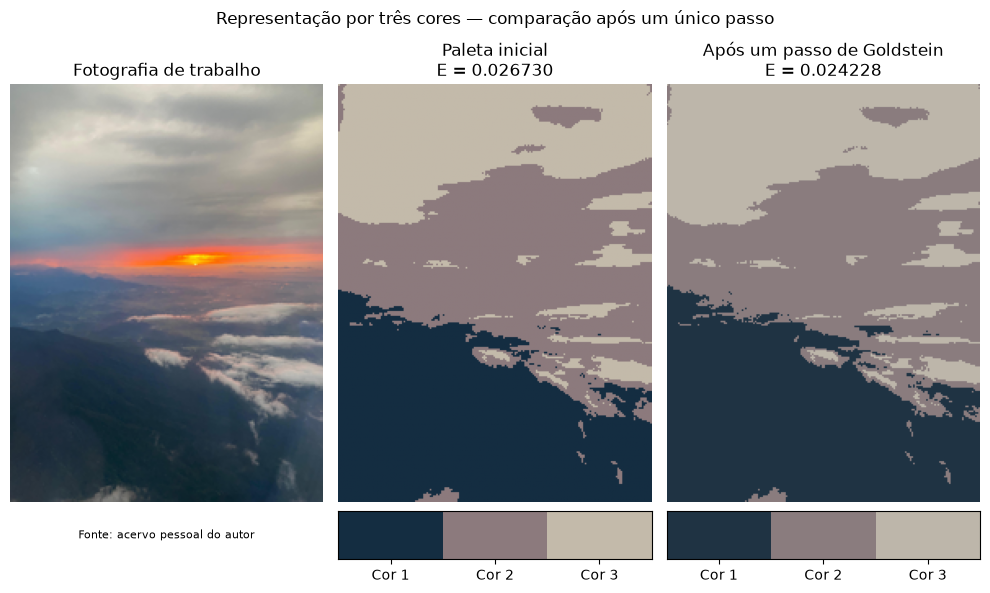

Saídas salvas em resultados/parte1:
 - comparacao_primeiro_passo.png
 - fotografia_trabalho.png
 - reconstrucao_inicial.png
 - reconstrucao_primeiro_passo.png
 - resultado_primeiro_passo.json


In [12]:
fig, eixos = plt.subplots(
    2, 3, figsize=(10, 6), gridspec_kw={"height_ratios": [10, 1]}
)
for ax, imagem, titulo in zip(
    eixos[0], (imagem_rgb, reconstrucao_inicial, reconstrucao_final),
    ("Fotografia de trabalho", f"Paleta inicial\nE = {E0:.6f}",
     f"Após um passo de Goldstein\nE = {E1:.6f}"),
):
    ax.imshow(np.clip(imagem, 0, 1))
    ax.set_title(titulo)
    ax.axis("off")
eixos[1, 0].axis("off")
eixos[1, 0].text(0.5, 0.5, "Fonte: acervo pessoal do autor", ha="center", va="center", fontsize=8)
for ax, paleta in zip(eixos[1, 1:], (paleta_inicial, paleta_final)):
    ax.imshow(np.clip(paleta[None, :, :], 0, 1), aspect="auto")
    ax.set_xticks([0, 1, 2], ["Cor 1", "Cor 2", "Cor 3"])
    ax.set_yticks([])
fig.suptitle("Representação por três cores — comparação após um único passo")
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "comparacao_primeiro_passo.png", dpi=160, bbox_inches="tight")
plt.show()

for nome, imagem in (
    ("fotografia_trabalho.png", imagem_rgb),
    ("reconstrucao_inicial.png", reconstrucao_inicial),
    ("reconstrucao_primeiro_passo.png", reconstrucao_final),
):
    rgb8 = np.rint(255 * np.clip(imagem, 0, 1)).astype(np.uint8)
    Image.fromarray(rgb8).save(PASTA_SAIDA / nome)

(PASTA_SAIDA / "resultado_primeiro_passo.json").write_text(
    json.dumps(resultado, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8"
)
print("Saídas salvas em resultados/parte1:")
for arquivo in sorted(PASTA_SAIDA.iterdir()):
    print(" -", arquivo.name)

## 13. Conclusão e leitura das saídas

O experimento comprova a redução estrita do objetivo suave em um passo de gradiente negativo, satisfazendo as duas condições de Goldstein. O erro da reconstrução por cor mais próxima é medido separadamente nas saídas da seção 11 e na figura, sem confundi-lo com o objetivo otimizado.

As verificações de diferenças finitas sustentam numericamente as derivadas nos dois pontos testados. A direção de curvatura negativa na seção 9 demonstra que, para a imagem e o parâmetro usados, a função não é globalmente convexa. A existência de um minimizador no cubo RGB não garante que o passo calculado o alcance.

**Como ler os arquivos:** `resultado_primeiro_passo.json` contém parâmetros, vetores inicial/final, gradiente, direção, objetivo, erro de reconstrução, histórico de tentativas, verificações de Goldstein, diagnóstico de convexidade e versões das bibliotecas. `comparacao_primeiro_passo.png` reúne fotografia, reconstruções e paletas. Os demais PNG permitem visualizar cada imagem separadamente.

**Limitações:** uma única fotografia, redução de resolução, RGB sem métrica perceptual, parâmetro de suavização fixo e apenas um passo. Não são feitas alegações de compressão de arquivo, melhora perceptual garantida ou convergência global. Os 27 experimentos TP e as três direções pertencem à Parte 2, em outro notebook.

**Uso de IA:** houve apoio na preparação dos dados, na formulação, nas derivadas, na implementação e nas verificações. As contribuições, os prompts e os erros corrigidos estão documentados nos arquivos de registro e no apêndice do relatório.